In [43]:
import EFC_learningfMRI.globals as gl
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import os
import EFC_learningfMRI.behaviour as behaviour
import EFC_learningfMRI.vis as vis
from EFC_learningfMRI.util import ttest_im_sess

figDir = gl.figDir

# Behavioural analysis
## Load data

In [44]:
path      = os.path.join(gl.baseDir, gl.behavDir)
perf      = pd.read_csv(os.path.join(path, 'behaviour.session.tsv'), sep='\t')
force     = pd.read_csv(os.path.join(path, 'force.session.avg.tsv'), sep='\t')
perf_rep  = pd.read_csv(os.path.join(path, 'behaviour.session.repetition.tsv'), sep='\t')
force_rep = pd.read_csv(os.path.join(path, 'force.session.repetition.avg.tsv'), sep='\t')

# the session tables above are averaged over the five fingers, so the only table left with
# the fingers as a variable -- i.e. the one that still holds the force patterns -- is the long one
force_long = pd.read_csv(os.path.join(path, 'force.trial.long.tsv'), sep='\t')
force_long['finger'] = force_long.finger.str.replace('_raw', '', regex=False)  # melted off the raw columns

print(f'N={perf.subNum.nunique()}')

N=16


## Example trials 
Execution of the same chord (92122) from participant 101 in session 1 and 24.


=== day 1 ===
trialPoint   0.000
MD             NaN
ET             NaN
RT             NaN
        F_avg  F_abs_avg  F_der_abs_avg
thumb    1.01       1.34           2.34
index   -2.20       2.20           3.65
middle   4.93       5.00           5.15
ring    -3.50       3.50          12.81
pinkie  -2.37       2.37           4.24

=== day 24 ===
trialPoint   1.000
MD           0.100
ET           0.066
RT           1.184
        F_avg  F_abs_avg  F_der_abs_avg
thumb    0.13       0.27           1.24
index   -2.87       2.87           1.35
middle   3.53       3.53           3.01
ring    -3.86       3.86           4.01
pinkie  -3.16       3.16           3.08


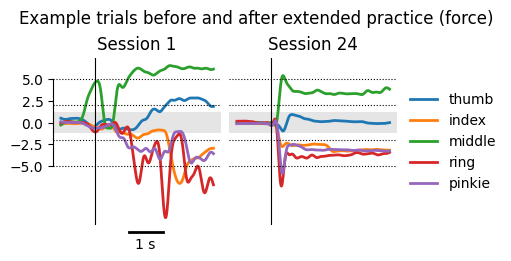

In [45]:
sn       = 101
n_block  = [1, 1]
sessions = [1, 24]
n_trial  = [12, 15]  # chord 92122

ch_idx = np.array(gl.diffCols)

tAx = np.linspace(-1, 3.5, int(gl.fsample['force'] * 4.5))

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(5, 2.5), constrained_layout=True,)

for s, sess in enumerate(sessions):
    ax = axs[s]

    fname = os.path.join(gl.baseDir, gl.behavDir, f'day{sess}', f'efc4_{sn}_{n_block[s]:02d}.mov')

    mov = behaviour.load_mov(fname)
    mov = mov[mov[:, 0] == n_trial[s]]
    mov = mov[(mov[:, 1] == gl.wait_exec) | (mov[:, 1] == gl.wait_exec - 1)]
    F   = mov[:, ch_idx] * gl.fGain

    is_last = s == len(sessions) - 1

    vis.plot_example_trial(ax, tAx, F, plot_legend=is_last)   # finger legend to the right of the last panel

    tinfo   = behaviour.analyse_trial(F, chordID=92122)
    scalars = {k: v for k, v in tinfo.items() if np.ndim(v) == 0}
    perFing = {k: v for k, v in tinfo.items() if np.ndim(v) > 0}

    ax.set_title(f'Session {sess}')

    # strip the axes: no x axis (the 1-s bar below replaces it); the y axis is shared, so only the first column keeps it
    sb.despine(ax=ax, trim=True, left=(s > 0), bottom=True)
    ax.tick_params(bottom=False, labelbottom=False)
    ax.set_xlabel(None)
    if s > 0:
        ax.tick_params(left=False, labelleft=False)

    print(f'\n=== day {sess} ===')
    print(pd.Series(scalars).to_string(float_format='{:.3f}'.format))
    print(pd.DataFrame(perFing, index=gl.fingers).round(2).to_string())

# 1-s scale bar under the first panel, from the go cue (t = 0) to t = 1 s
# x in data units (seconds), y in axes units, so the bar sits just below the panel whatever the force range
ax    = axs[0]
trans = ax.get_xaxis_transform()
ax.plot([1, 2], [-.04, -.04], color='k', lw=2, transform=trans, clip_on=False)
ax.text(1.5, -.07, '1 s', transform=trans, ha='center', va='top')

fig.suptitle('Example trials before and after extended practice (force)')

fig.savefig(os.path.join(figDir, 'example_trials.pdf'))

plt.show()

## Force patterns
Average force pattern of each chord on session 23, taken from `force.trial.long.tsv` — the only behavioural table that keeps the five fingers as a variable rather than averaging over them. Each panel is one chord: the signed force of each finger, averaged over successful trials within a participant and then over participants (error bars are s.e.m. across participants). Every chord is trained in half of the participants and untrained in the other half (8 vs 8), so the two lines are between-participant comparisons of the same physical chord. The grey markers show the instructed direction of each finger (up = extension, down = flexion, nothing = finger not instructed): the measured patterns follow the instruction in every chord, and trained and untrained patterns are hardly distinguishable.

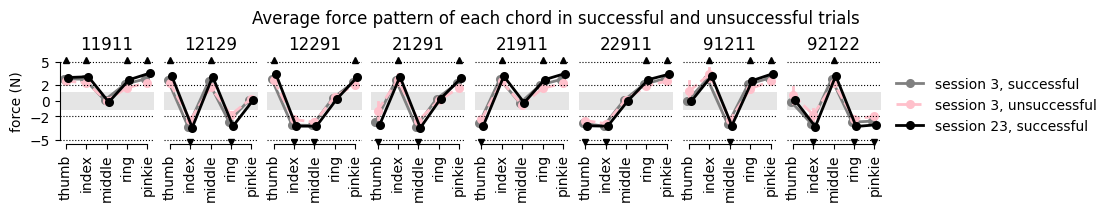

In [46]:
sessions = [3, 23]

# session 3: successful (trialPoint == 1) and unsuccessful (trialPoint == 0) trials
early = force_long[force_long.session == sessions[0]].copy()
early['outcome'] = early.trialPoint.map({1: f'session {sessions[0]}, successful', 0: f'session {sessions[0]}, unsuccessful'})

# session 23: successful trials only
late = force_long[(force_long.session == sessions[1]) & (force_long.trialPoint == 1)].copy()
late['outcome'] = f'session {sessions[1]}, successful'

# one pattern per participant x chord x outcome
pattern = pd.concat([early, late], ignore_index=True)
pattern = pattern.groupby(['subNum', 'chordID', 'finger', 'outcome'], observed=True)[['force_raw']].mean().reset_index()

hue_order  = [f'session {sessions[0]}, successful', f'session {sessions[0]}, unsuccessful', f'session {sessions[1]}, successful']
palette    = ['grey', 'pink', 'black']
linestyles = ['-', '--', '-']   # unsuccessful dotted

fig, axs = plt.subplots(1, 8, figsize=(11, 2), sharey=True, constrained_layout=True)
# ls=None drops plot_force_pattern's default solid line, which would otherwise override linestyles
vis.plot_force_pattern(fig, axs, pattern, y='force_raw', hue='outcome', hue_order=hue_order, palette=palette, add_zero=False, ls=None, linestyles=linestyles)
axs[0].set_ylabel('force (N)')
axs[0].set_yticks([-5, -2, 0, 2, 5])
axs[-1].legend([], frameon=False)
fig.legend(frameon=False, loc='outside right center')
fig.suptitle(f'Average force pattern of each chord in successful and unsuccessful trials')

fig.savefig(os.path.join(figDir, 'force_pattern_success.pdf'))

plt.show()

## Success rate
A trial was considered successful if the participant was able to achieve the instructed chord and hold it for at least 600ms within a 3.5s time-window, and until then end of the trial. Success rate was similar between trained and untrained chords in sessions 3 and 23, and only marginally higher in trained chords on session 9.

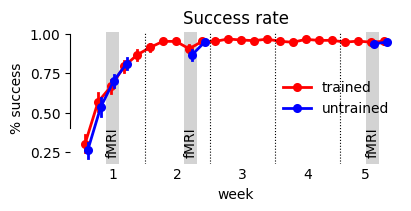

In [47]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)

ax.spines['left'].set_bounds(.4, 1)
ax.set_ylabel('% success')
ax.set_title('Success rate')

vis.plot_behav_sess(fig, ax, perf, x='session', y='trialPoint', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'success.pdf'))


In [48]:
ttest = ttest_im_sess(perf[perf.session_type=='scanning'], y='trialPoint', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

 session       A         B         T  dof    p_val          CI95  cohen_d  BF10
       3 trained untrained -1.194764   15 0.250729  [-0.1, 0.03] 0.214437 0.469
       9 trained untrained  1.839564   15 0.085707 [-0.01, 0.09] 0.368657 0.997
      23 trained untrained  1.536348   15 0.145276  [-0.0, 0.03] 0.205738 0.679


## Execution time
Execution time was calculated from the moment the participant exited with any finger from the baseline force range (i.e., ±`gl.thresh`) and the time the instructed fingers entered the target force range (i.e., `gl.ftarget` + 3N). Trained chords were executed significantly faster than untrained chords on sessions 9 and 23.

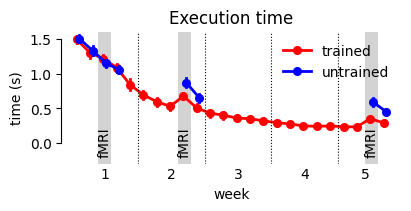

In [49]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((-.3, 1.6))
ax.spines['left'].set_bounds(0, 1.5)
ax.set_ylabel('time (s)')
ax.set_title('Execution time')
vis.plot_behav_sess(fig, ax, perf, x='session', y='ET', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'execution_time.pdf'))

In [50]:
ttest = ttest_im_sess(perf[perf.session.isin(gl.sessions)], y='ET', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

 session       A         B         T  dof    p_val           CI95  cohen_d    BF10
       3 trained untrained  1.336190   15 0.201405  [-0.04, 0.16] 0.289567   0.542
       9 trained untrained -4.145954   15 0.000862  [-0.3, -0.09] 0.882391  43.477
      23 trained untrained -5.087928   15 0.000134 [-0.34, -0.14] 1.370487 220.906


## Mean deviation
Mean deviation was calculated using `EFC_learning.behaviour.calc_MD()` as the average Euclidean distance between the force trajectory in the five-finger space and the straight line joining the force at the beginning and at the end of the execution (i.e., over the same time window used for execution time). Trained chords were executed with significantly smaller deviations than untrained chords on sessions 9 and 23. 

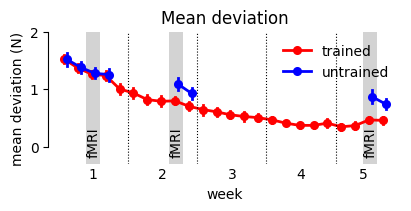

In [51]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((-.3, 2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('mean deviation (N)')
ax.set_title('Mean deviation')
# ax.axhline(perf[(perf.chord=='untrained') & (perf.session==9)].MD.mean(), color='b', lw=.8)
# ax.axhline(perf[(perf.chord=='untrained') & (perf.session==23)].MD.mean(), color='b', lw=.8)
vis.plot_behav_sess(fig, ax, perf, x='session', y='MD', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

fig.savefig(os.path.join(figDir, 'mean_deviation.pdf'))

In [52]:
ttest = ttest_im_sess(perf[perf.session.isin(gl.sessions)], y='MD', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))
plt.show()

 session       A         B         T  dof    p_val           CI95  cohen_d    BF10
       3 trained untrained -0.256124   15 0.801334  [-0.15, 0.12] 0.052760   0.263
       9 trained untrained -4.274223   15 0.000665 [-0.44, -0.15] 0.872960   54.38
      23 trained untrained -5.229773   15 0.000102 [-0.57, -0.24] 1.216861 280.744


## Absolute force
Absolute force was calculated as the average absolute force of each finger, from the moment the participant exited the baseline force range (i.e., ±`gl.fthresh`) until the end of the trial, and was then averaged across the five fingers and across successful trials. Absolute force increased slightly over sessions, but did not differ significantly between trained and untrained chords in any of the scanning sessions.

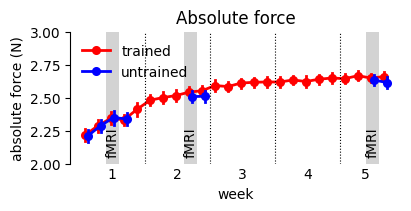

In [53]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((2, 3))
ax.spines['left'].set_bounds(2, 3)
ax.set_ylabel('absolute force (N)')
ax.set_title('Absolute force')

vis.plot_behav_sess(fig, ax, force, x='session', y='force_abs', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])

ax.legend(loc='upper left', frameon=False)

fig.savefig(os.path.join(figDir, 'force_abs.pdf'))

In [54]:
ttest = ttest_im_sess(force[force.session.isin(gl.sessions)], y='force_abs', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

 session       A         B         T  dof    p_val          CI95  cohen_d  BF10
       3 trained untrained -0.192669   15 0.849802 [-0.05, 0.05] 0.022645  0.26
       9 trained untrained  1.666232   15 0.116407 [-0.01, 0.08] 0.211804 0.796
      23 trained untrained  0.693541   15 0.498570 [-0.03, 0.06] 0.102358 0.315


## Mean force derivative
The force derivative was calculated as the average absolute first derivative of the force of each finger, over the same time window used for absolute force, and was then averaged across the five fingers and across successful trials. Trained chords were produced with a significantly lower force derivative than untrained chords on sessions 9 and 23.

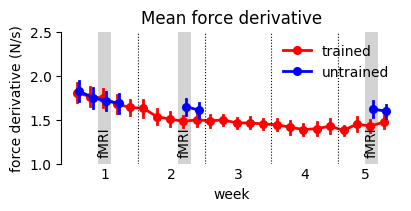

In [55]:
fig, ax = plt.subplots(figsize=(4,2), constrained_layout=True)
ax.set_ylim((1, 2.5))
ax.spines['left'].set_bounds(1, 2.5)
ax.set_ylabel('force derivative (N/s)')
ax.set_title('Mean force derivative')
vis.plot_behav_sess(fig, ax, force, x='session', y='force_der', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'])
ax.legend(loc='upper right', frameon=False)
fig.savefig(os.path.join(figDir, 'force_der.pdf'))

In [56]:
ttest = ttest_im_sess(force[force.session.isin(gl.sessions)], y='force_der', hue='chord', hue_order=['trained', 'untrained'], roi_col=None, subject_col='subNum')
print(ttest[['session', 'A', 'B', 'T', 'dof', 'p_val', 'CI95', 'cohen_d', 'BF10']].to_string(index=False))

plt.show()

 session       A         B         T  dof    p_val           CI95  cohen_d   BF10
       3 trained untrained  0.666834   15 0.515005  [-0.07, 0.13] 0.079443  0.311
       9 trained untrained -4.213709   15 0.000752 [-0.25, -0.08] 0.531242 48.934
      23 trained untrained -3.679242   15 0.002232  [-0.3, -0.08] 0.588636 19.241


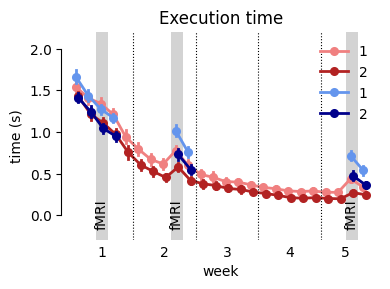

In [57]:
fig, ax = plt.subplots(figsize=(4,3),)
ax.set_ylim((-.3, 2.2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('time (s)')
ax.set_title('Execution time')
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='trained'], x='session', y='ET', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='untrained'], x='session', y='ET', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_execution_time.pdf'))
plt.show()

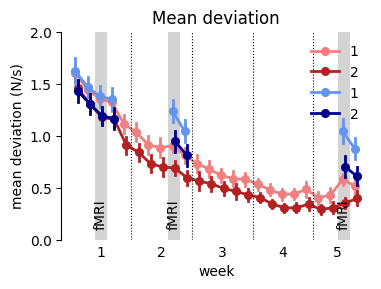

In [58]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((0, 2))
ax.spines['left'].set_bounds(0, 2)
ax.set_ylabel('mean deviation (N/s)')
ax.set_title('Mean deviation')
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='trained'], x='session', y='MD', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, perf_rep[perf_rep.chord=='untrained'], x='session', y='MD', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='upper right', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_mean_deviation.pdf'))
plt.show()

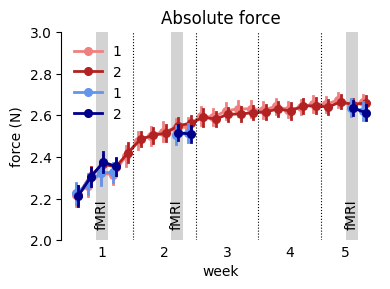

In [59]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((2, 3))
ax.spines['left'].set_bounds(2, 3)
ax.set_ylabel('force (N)')
ax.set_title('Absolute force')
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='trained'], x='session', y='force_abs', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='untrained'], x='session', y='force_abs', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
ax.legend(loc='best', frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_force_absolute.pdf'))
plt.show()

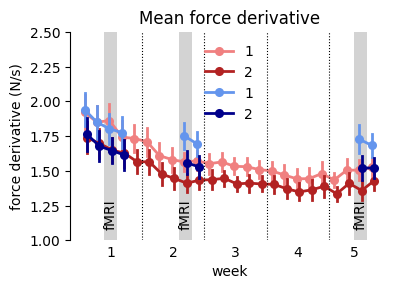

In [60]:
fig, ax = plt.subplots(figsize=(4,3))
ax.set_ylim((1, 2.5))
ax.spines['left'].set_bounds(1, 2.5)
ax.set_ylabel('force derivative (N/s)')
ax.set_title('Mean force derivative')
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='trained'], x='session', y='force_der', hue='Repetition', palette=['lightcoral', 'firebrick'], decor=False)
vis.plot_behav_sess(fig, ax, force_rep[force_rep.chord=='untrained'], x='session', y='force_der', hue='Repetition', palette=['cornflowerblue', 'darkblue'], decor=True)
fig.tight_layout()
fig.savefig(os.path.join(figDir, 'rep_force_derivative.pdf'))
plt.show()

## Behaviour figure
A example trials; B–D success rate, execution time and mean deviation across sessions, stacked on a common session axis; E force patterns. Every axes has a fixed size in inches, so each panel keeps roughly the proportions of its standalone version. Saved as `behaviour.pdf`.

In [ ]:
# behaviour figure, 7.2 in wide (double column). Every axes is placed at a fixed size in inches,
# so each panel keeps roughly the width/height ratio of its standalone version:
#   example trials ~1 : 1, session measures ~2.6 : 1, force patterns ~0.85 : 1
# layout: A example trials (2 panels)  | B success rate
#         E force patterns, 2 rows x 4 | C execution time
#                                      | D mean deviation
style = {'font.size'        : 7,
         'axes.titlesize'   : 7,
         'axes.labelsize'   : 7,
         'xtick.labelsize'  : 6,
         'ytick.labelsize'  : 6,
         'legend.fontsize'  : 6,
         'axes.linewidth'   : .6,
         'xtick.major.width': .6,
         'ytick.major.width': .6,
         'xtick.major.size' : 2.5,
         'ytick.major.size' : 2.5,
         'lines.linewidth'  : 1,
         'pdf.fonttype'     : 42}   # editable text in the pdf

W, H = 7.2, 5.1    # figure size (in)

# axes positions in inches: (left, bottom, width, height)
pos_ex   = [(.45, 3.50, 1.30, 1.30), (1.95, 3.50, 1.30, 1.30)]
pos_sess = [(3.85, 3.70, 3.25, 1.25), (3.85, 2.25, 3.25, 1.25), (3.85, .80, 3.25, 1.25)]
pat_w, pat_h, pat_gap = .625, .75, .1
pos_pat  = [(.45 + c * (pat_w + pat_gap), 2.00, pat_w, pat_h) for c in range(4)] + \
           [(.45 + c * (pat_w + pat_gap), .80,  pat_w, pat_h) for c in range(4)]

chord_sets = ['trained', 'untrained']
set_colors = ['red', 'blue']   # same as the standalone panels
point_kws  = dict(lw=1, markersize=2.5, err_kws={'linewidth': .8})

with plt.rc_context(style):
    fig = plt.figure(figsize=(W, H))

    # A: example trials
    sn      = 101
    n_block = [1, 1]
    ex_sess = [1, 24]
    n_trial = [12, 15]  # chord 92122
    ch_idx  = np.array(gl.diffCols)
    tAx     = np.linspace(-1, 3.5, int(gl.fsample['force'] * 4.5))
    axs_ex  = []
    for s, sess in enumerate(ex_sess):
        x, y, w, h = pos_ex[s]
        sharey     = axs_ex[0] if s > 0 else None
        ax         = fig.add_axes([x / W, y / H, w / W, h / H], sharey=sharey)
        axs_ex.append(ax)
        filename = os.path.join(gl.baseDir, gl.behavDir, f'day{sess}', f'efc4_{sn}_{n_block[s]:02d}.mov')
        mov      = behaviour.load_mov(filename)
        mov      = mov[mov[:, 0] == n_trial[s]]
        mov      = mov[(mov[:, 1] == gl.wait_exec) | (mov[:, 1] == gl.wait_exec - 1)]
        F        = mov[:, ch_idx] * gl.fGain
        vis.plot_example_trial(ax, tAx, F)
        for line in ax.lines[:5]:          # the five finger traces; plot_example_trial draws them at lw=2
            line.set_linewidth(1)
        ax.set_title(f'session {sess}')
        sb.despine(ax=ax, trim=True, left=(s > 0), bottom=True)
        ax.tick_params(bottom=False, labelbottom=False)
        ax.set_xlabel(None)
        if s > 0:
            ax.tick_params(left=False, labelleft=False)
    axs_ex[0].set_ylabel('force (N)')
    axs_ex[0].set_yticks([-5, 0, 5])
    trans = axs_ex[0].get_xaxis_transform()
    axs_ex[0].plot([1, 2], [-.04, -.04], color='k', lw=1.5, transform=trans, clip_on=False)
    axs_ex[0].text(1.5, -.07, '1 s', transform=trans, ha='center', va='top')
    # finger legend between the example trials and the force patterns
    handles, labels = axs_ex[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(1.85 / W, 3.08 / H), ncol=5, frameon=False,
               handlelength=1.2, columnspacing=.8)

    # B-D: one row per measure, stacked on the same session axis
    measures = [('trialPoint', 'success rate',        (.2, 1.05), (.25, 1), [.25, .5, .75, 1]),
                ('ET',         'execution time (s)',  (-.3, 1.6), (0, 1.5), [0, .5, 1, 1.5]),
                ('MD',         'mean deviation (N)',  (-.3, 2),   (0, 2),   [0, 1, 2])]
    axs_sess = []
    for m, (y_col, ylabel, ylim, bounds, yticks) in enumerate(measures):
        x, y, w, h = pos_sess[m]
        sharex     = axs_sess[0] if m > 0 else None
        ax         = fig.add_axes([x / W, y / H, w / W, h / H], sharex=sharex)
        axs_sess.append(ax)
        ax.set_ylim(ylim)
        ax.spines['left'].set_bounds(*bounds)
        vis.plot_behav_sess(fig, ax, perf, x='session', y=y_col, hue='chord', hue_order=chord_sets, palette=set_colors, legend=(m == 1), **point_kws)
        ax.set_yticks(yticks)
        ax.set_ylabel(ylabel)
        is_top    = m == 0
        is_bottom = m == len(measures) - 1
        # 'fMRI' labels on the top row only, week labels on the bottom row only
        for t in list(ax.texts):
            is_fmri = t.get_text() == 'fMRI'
            drop    = (is_fmri and not is_top) or (not is_fmri and not is_bottom)
            if drop:
                t.remove()
    sb.move_legend(axs_sess[1], 'upper right', frameon=False, title=None, handlelength=1.2)

    # E: force patterns, session 3 successful / unsuccessful and session 23 successful
    pat_sess = [3, 23]
    early    = force_long[force_long.session == pat_sess[0]].copy()
    early['outcome'] = early.trialPoint.map({1: f'session {pat_sess[0]}, successful', 0: f'session {pat_sess[0]}, unsuccessful'})
    late     = force_long[(force_long.session == pat_sess[1]) & (force_long.trialPoint == 1)].copy()
    late['outcome'] = f'session {pat_sess[1]}, successful'
    pattern  = pd.concat([early, late], ignore_index=True)
    pattern  = pattern.groupby(['subNum', 'chordID', 'finger', 'outcome'], observed=True)[['force_raw']].mean().reset_index()
    pat_order  = [f'session {pat_sess[0]}, successful', f'session {pat_sess[0]}, unsuccessful', f'session {pat_sess[1]}, successful']
    pat_colors = ['grey', 'pink', 'black']
    pat_styles = ['-', '--', '-']
    axs_pat = []
    for c, (x, y, w, h) in enumerate(pos_pat):
        sharey = axs_pat[0] if c > 0 else None
        ax     = fig.add_axes([x / W, y / H, w / W, h / H], sharey=sharey)
        axs_pat.append(ax)
    vis.plot_force_pattern(fig, axs_pat, pattern, y='force_raw', hue='outcome', hue_order=pat_order, palette=pat_colors, add_zero=False, ls=None, linestyles=pat_styles, **point_kws)
    finger_initials = [f[0].upper() for f in gl.fingers]
    for ax in axs_pat:
        ax.set_xticks(range(len(gl.fingers)), finger_initials, rotation=0)
        for line in ax.lines:              # instructed-direction triangles, drawn at ms=4
            is_marker = line.get_marker() in ('^', 'v')
            if is_marker:
                line.set_markersize(2.5)
    # plot_force_pattern keeps the y axis on the first panel only; the second row starts at panel 4
    first_of_row2 = axs_pat[4]
    first_of_row2.spines['left'].set_visible(True)
    first_of_row2.tick_params(left=True, labelleft=True)
    sb.despine(ax=first_of_row2, trim=True)
    for ax in (axs_pat[0], first_of_row2):
        ax.set_ylabel('force (N)')
        ax.set_yticks([-5, 0, 5])
    # force-pattern legend along the bottom of the figure
    handles, labels = axs_pat[-1].get_legend_handles_labels()
    axs_pat[-1].get_legend().remove()
    fig.legend(handles, labels, loc='center', bbox_to_anchor=(.5, .22 / H), ncol=3, frameon=False, handlelength=1.6)

    # panel letters, in inches from the bottom left
    letters = {'A': (.05, 5.05), 'B': (3.35, 5.05), 'C': (3.35, 3.60), 'D': (3.35, 2.15), 'E': (.05, 2.95)}
    for letter, (x, y) in letters.items():
        fig.text(x / W, y / H, letter, fontsize=9, fontweight='bold', ha='left', va='top')

    fig.savefig(os.path.join(figDir, 'behaviour.pdf'))

    plt.show()